# 01 · Análise exploratória do painel

*Dados: dunnhumby Source Files – Breakfast at the Frat.* A análise descreve o painel sem ajuste de modelos. As funções de `src/retail_multilevel` geram as tabelas e os gráficos agregados. Os dados brutos são licenciados e ficam fora do repositório.

In [1]:
LANG = "pt"

In [2]:
import warnings

import pandas as pd
from IPython.display import display

from retail_multilevel import eda, viz
from retail_multilevel.i18n import t
from retail_multilevel.paths import PROCESSED_DIR
from retail_multilevel.split import model_sample

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.3f}".format)
panel = pd.read_parquet(PROCESSED_DIR / "panel.parquet")
train = model_sample(panel, "train")
test = model_sample(panel, "test")
print(t("data_credit", LANG))

Dados: dunnhumby Source Files – Breakfast at the Frat


## Briefing: como funciona o negócio

As definições vêm do guia do usuário e da aba *Glossary* do arquivo da dunnhumby. As contagens foram calculadas a partir do painel.

O painel reúne vendas de 77 lojas de uma rede varejista em quatro estados dos EUA. O guia omite o nome da rede e registra 79 linhas na tabela de lojas. A rede classificou cada loja como *Value*, *Mainstream* ou *Upscale*. O guia descreve esses segmentos como patamares de preço e deixa em aberto como foram definidos. Nas lojas 4503 e 17627, o cadastro traz dois segmentos distintos, tratados como ambíguos.

In [3]:
stores = panel.drop_duplicates("STORE_NUM")
display(
    pd.crosstab(
        stores["STATE"],
        stores["SEGMENT"].fillna(t("segment_ambiguous", LANG)),
        margins=True,
        margins_name=t("all_rows", LANG),
    )
)

SEGMENT,Ambíguo,MAINSTREAM,UPSCALE,VALUE,Todos
STATE,,,,,
IN,0,1,0,0,1
KY,0,3,0,1,4
OH,0,16,7,8,31
TX,2,21,8,10,41
Todos,2,41,15,19,77


São acompanhadas quatro categorias, que incluem enxaguantes bucais (`ORAL HYGIENE PRODUCTS`), pretzels (`BAG SNACKS`), pizza congelada (`FROZEN PIZZA`) e cereal em caixa (`COLD CEREAL`). Dos 55 produtos (UPCs), 43 são de marcas nacionais e 12 de marca própria da rede (`PRIVATE LABEL` no campo de fabricante), com três de marca própria em cada categoria. Há 15 outros fabricantes.

In [4]:
products = panel.drop_duplicates("UPC")
by_category = pd.crosstab(
    [products["CATEGORY"], products["SUB_CATEGORY"]],
    products["PRIVATE_LABEL"].map({False: t("brand_national", LANG), True: t("brand_private", LANG)}),
    margins=True,
    margins_name=t("all_rows", LANG),
)
display(by_category)
display(pd.Series({t("n_manufacturers", LANG): products["MANUFACTURER"].nunique()}).to_frame("n"))

PRIVATE_LABEL                                      Marca nacional  Marca própria  Todos
CATEGORY              SUB_CATEGORY                                                     
BAG SNACKS            PRETZELS                                 12              3     15
COLD CEREAL           ADULT CEREAL                              2              1      3
                      ALL FAMILY CEREAL                         5              2      7
                      KIDS CEREAL                               5              0      5
FROZEN PIZZA          PIZZA/PREMIUM                             9              3     12
ORAL HYGIENE PRODUCTS MOUTHWASH/RINSES AND SPRAYS               5              0      5
                      MOUTHWASHES (ANTISEPTIC)                  5              3      8
Todos                                                          43             12     55

,n
Fabricantes (incl. marca própria),16


Cada linha do painel corresponde a um produto (UPC) em uma loja em uma semana. O painel cobre 156 semanas, de 2009-01-14 a 2012-01-04 pelas datas de encerramento.

`UNITS` conta as unidades vendidas e `SPEND` registra o faturamento em dólares. `VISITS` conta as cestas que incluíram ao menos uma unidade do produto, e `HHS` conta os domicílios que o compraram. O desconto é calculado comparando `PRICE`, o preço pago na loja, com `BASE_PRICE`, o preço de referência do item.

### Promoções semanais

A **TPR** (*temporary price reduction*, `TPR_ONLY`) é um corte temporário de preço, comunicado pelo valor na prateleira. O **encarte** (*feature*, `FEATURE`) indica que o produto apareceu no folheto de ofertas. O **display** (`DISPLAY`) indica que o produto teve um ponto de exposição especial na loja.

A seção 4 confirma que `TPR_ONLY` só aparece em linhas sem encarte nem display. Encarte e display podem ocorrer juntos.

### Preço, promoção e margem

Um preço menor ou uma promoção pode aumentar as unidades vendidas, com redução da margem unitária e, em alguns casos, custos de promoção. A **elasticidade-preço** mede a variação percentual das unidades associada a uma variação de 1% no preço (Tellis, 1988; Bijmolt et al., 2005). Com elasticidade de −2, um corte de 10% no preço corresponde a cerca de 20% mais unidades pela aproximação −2 × −10%. No modelo logarítmico de elasticidade constante, o cálculo exato é 0,9<sup>−2</sup> − 1 ≈ 23,5%. O **lift de promoção** mede o aumento das unidades em semanas com promoção em relação a semanas sem ela (Blattberg & Neslin, 1989).

A resposta ao preço e às promoções pode variar entre lojas e produtos. Muitos pares loja × produto têm poucas semanas ou pouca variação de preço. Quando cada par é ajustado separadamente, as elasticidades podem ficar muito dispersas e até trocar de sinal, como mostra a seção 8. Uma elasticidade única, por sua vez, deixa de representar diferenças entre pares. Com *partial pooling* (agrupamento parcial), os **modelos multinível** combinam a informação de vários grupos. As estimativas dos grupos com menos informação ficam mais próximas da média (Gelman & Hill, 2007; Raudenbush & Bryk, 2002).

## A pergunta-chave

**Como as vendas se associam ao preço e às promoções em cada loja e produto?** O guia pergunta para quais produtos vale reduzir o preço para vender mais ou aumentá-lo para melhorar o lucro. Essas perguntas orientam a análise de cenários do projeto.

A análise começa pela variação das vendas entre lojas, produtos e pares loja × produto, e entre semanas do mesmo par. Em seguida são estimadas a elasticidade-preço média e as associações com encarte, display e TPR. Segmento da loja, categoria e marca própria entram na análise das diferenças de elasticidade.

A previsão fora da amostra compara o multinível com uma regressão de nível único (OLS) e com o GPBoost (Sigrist, 2022). Nos cenários, os coeficientes representam associações condicionais em semanas com transações registradas. Identificação causal e dados de margem seriam necessários para recomendar preços ou calcular o ROI incremental.

## Guia de leitura

| Notebook | Conteúdo | Situação |
|---|---|---|
| 01 | Análise exploratória do painel (este) | Disponível |
| 02 | Modelo nulo: decomposição da variância | Disponível |
| 03 | Efeitos fixos de preço e promoção, com sensibilidades e diagnóstico residual | Disponível |
| 04 | Protocolo P1: inclinações aleatórias e comparação fora da amostra | Disponível |
| 05 | Contrastes planejados do desconto (segmento, marca própria e categoria) e sensibilidade a choques de categoria × semana | Disponível |
| 06 | Cenários de preço e promoção, com intervalos pela covariância conjunta e suporte observado | Disponível |

## Glossário

| Termo | Significado |
|---|---|
| UPC | Código universal do produto (identificador do produto) |
| Par | Combinação de uma loja com um produto (loja × produto) |
| Cesta (*visit*) | Cada compra em que o produto entrou ao menos uma vez |
| Preço base | Preço regular do item, sem desconto temporário; a comparação com o preço de gôndola dá o desconto (no painel, o preço só fica abaixo do base em semanas com promoção) |
| TPR | Corte de preço por tempo limitado, percebido só pelo preço marcado na prateleira |
| Encarte (*feature*) | Produto anunciado no folheto de ofertas da loja |
| Display | Produto com ponto de exposição especial dentro da loja |
| Elasticidade-preço | Variação percentual das unidades para 1% de variação no preço |
| Lift de promoção | Aumento das unidades em semanas com a promoção, frente a semanas sem ela |
| *Partial pooling* | Estimar cada grupo usando também a informação dos demais, o que aproxima as estimativas de pouca informação da média |
| ICC | Correlação prevista entre observações que compartilham um ou mais agrupamentos |
| BLUP | Desvio previsto de um grupo em relação à média, já encolhido em direção a zero |
| Treino / teste | As primeiras 104 semanas ajustam os modelos; as últimas 52 formam a janela de avaliação temporal retrospectiva, com exposição exploratória prévia |

## Quais variáveis entram na análise?

Cada linha do painel agregado representa um UPC em uma loja em uma semana observada. A mesma loja e o mesmo produto aparecem em muitas linhas. Seus códigos identificam as unidades, enquanto preço e promoção descrevem as condições daquela semana. O quadro distingue a resposta, os preditores e as informações de contexto.

| Colunas no painel | O que representam | Papel na análise |
|---|---|---|
| `STORE_NUM`, `UPC`, `WEEK_END_DATE` | Código da loja, código do produto e data de fim da semana | Chave da observação semanal. `PAIR_ID` identifica a combinação loja × UPC ao longo do tempo. |
| `UNITS`, `LOG_UNITS` | Quantidade vendida e seu logaritmo natural | `LOG_UNITS` é a variável-resposta do modelo principal. |
| `PRICE`, `BASE_PRICE` | Preço de gôndola e preço regular, por unidade do produto | A comparação entre os dois dá o desconto. Ausências de preço regular são tratadas e sinalizadas na limpeza. |
| `FEATURE`, `DISPLAY`, `TPR_ONLY` | Encarte, exposição especial e redução temporária de preço sem encarte nem display, respectivamente | Indicadores 0/1 usados como preditores. O nome `FEATURE` nesta base significa encarte. |
| `WEEK`, `WEEK_OF_YEAR` | Índice sequencial da semana e número da semana no calendário ISO | Origem dos controles de tendência e sazonalidade. |
| `SEGMENT`, `CATEGORY`, `PRIVATE_LABEL` | Segmento da loja, categoria e indicador de marca própria | Moderadores da associação com desconto no notebook 05. Esses atributos são constantes dentro de um par. |
| `VISITS`, `HHS`, `SPEND` | Cestas que incluíram o produto, domicílios compradores e gasto total | Medidas observadas na mesma semana, usadas para descrição e controle de qualidade, fora dos preditores do C0. |
| `CITY`, `STATE`, `MSA_CODE`, `SALES_AREA`, `AVG_WEEKLY_BASKETS` | Localização e características da loja | Contexto do cadastro, fora dos preditores do C0. |

### Como os preditores do C0 são construídos

| Variável usada no modelo | Construção | Interpretação |
|---|---|---|
| `LOG_DISC` | `ln(PRICE / BASE_PRICE)` | É zero quando os preços coincidem e negativo quando há desconto. |
| `LOG_BASE_MEAN` | Média de `ln(BASE_PRICE)` do par na janela de ajuste | Representa o nível de preço regular do par. Em um par novo com UPC conhecido, é usada a média do UPC na janela de ajuste. |
| `LOG_BASE_DEV` | `ln(BASE_PRICE) − LOG_BASE_MEAN` | Mede o quanto o preço regular da semana se desvia da referência do par. |
| `FEATURE`, `DISPLAY`, `TPR_ONLY` | Indicadores registrados na semana | Identificam a modalidade de promoção com a profundidade do desconto incluída no mesmo modelo. |
| `TREND`, `SIN_1` a `SIN_3`, `COS_1` a `COS_3` | Índice da semana em anos e três pares de termos de Fourier do calendário (Hyndman & Athanasopoulos, 2021) | Representam a tendência e a sazonalidade anual. |

Por exemplo, um preço de 1,80 para um preço regular de 2,00 corresponde a um desconto de 10% e a `LOG_DISC` de aproximadamente −0,105. As chaves de loja, produto e par ligam a observação aos respectivos interceptos aleatórios. No C0, os coeficientes dos preditores da tabela são comuns aos grupos.

## O painel tem dois ou três níveis?

Há **dois níveis na parte aninhada**: a observação semanal e o par loja × UPC, que é a unidade acompanhada ao longo do tempo. O modelo também agrupa os pares por loja e por UPC. Esses dois agrupamentos são **cruzados** (Baayen et al., 2008): a loja A vende mais de um UPC e o UPC A aparece em mais de uma loja.

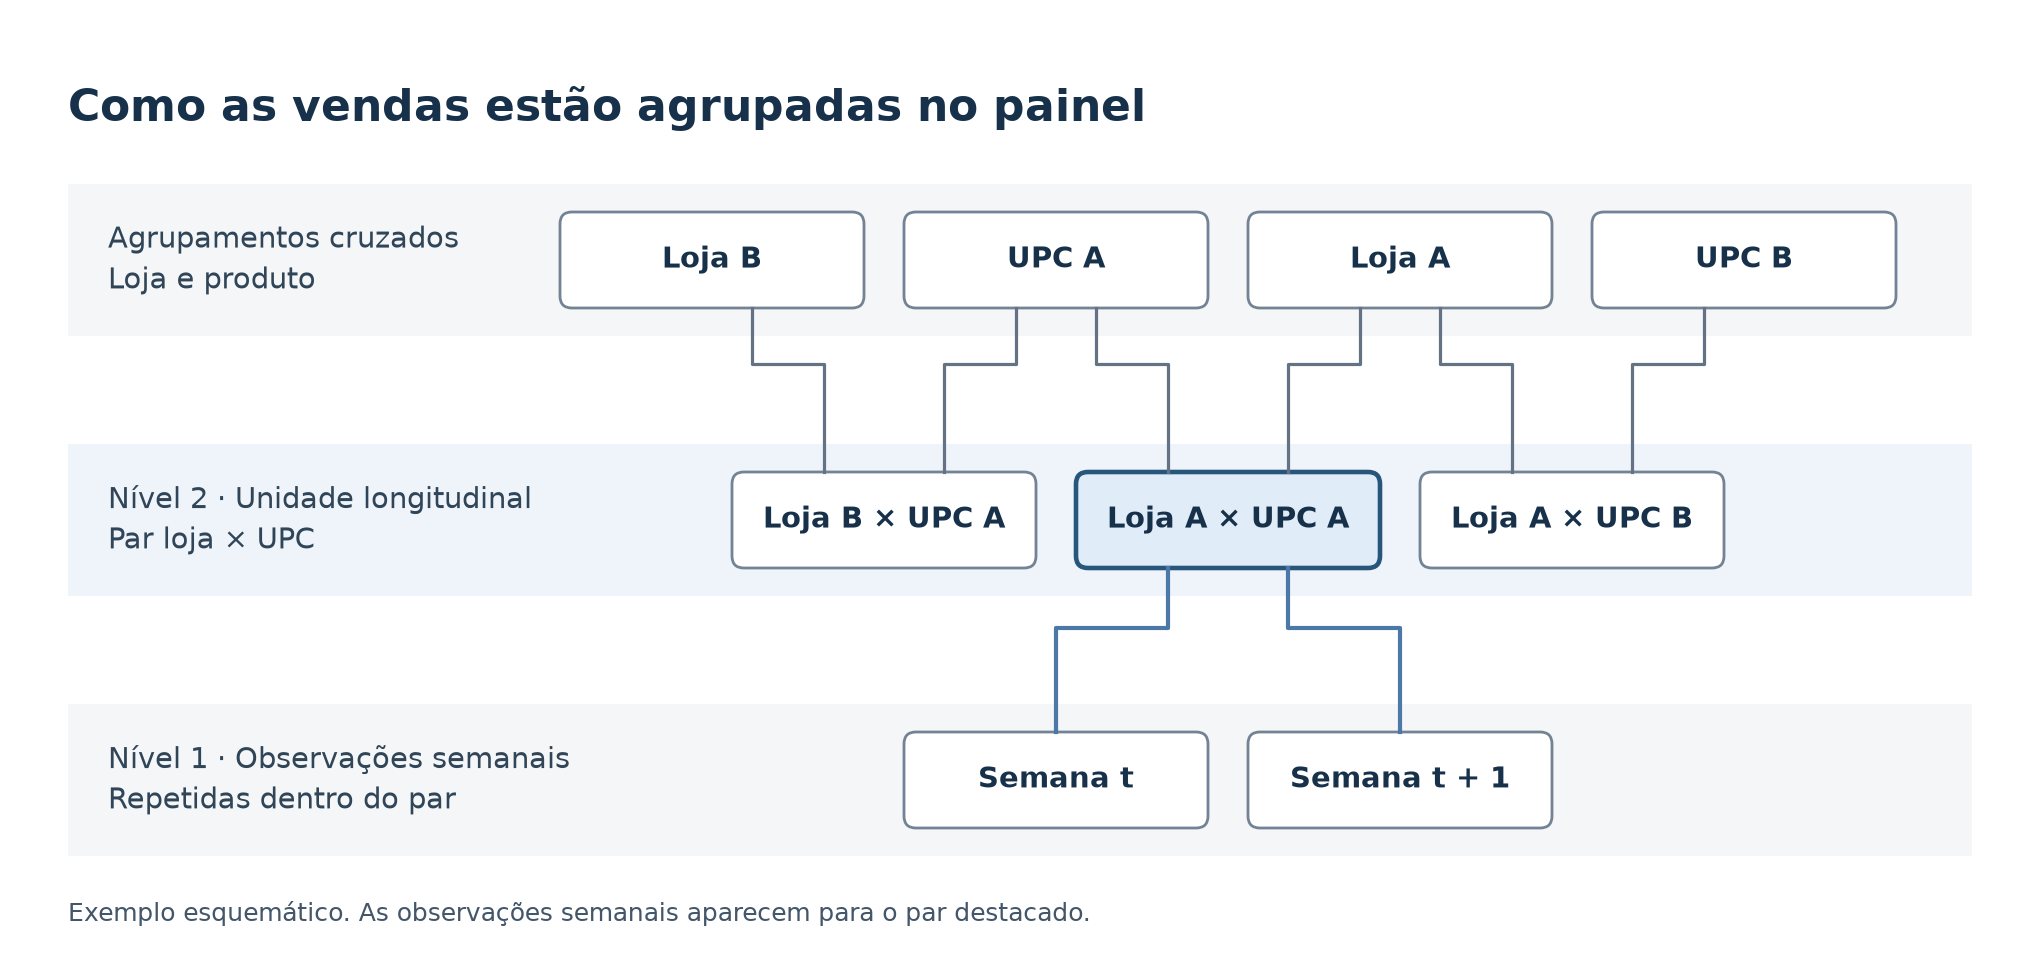

In [5]:
fig = viz.plot_panel_structure(LANG)

A figura usa **três faixas** para mostrar os agrupamentos cruzados, os pares e suas observações semanais. O C0 estima interceptos aleatórios de loja, UPC e par (`STORE_NUM:UPC`). Semanas do mesmo par compartilham os três interceptos. Pares distintos podem compartilhar apenas a loja ou apenas o UPC. A semana do calendário é comum aos pares observados naquela data e, no C0, entra por controles fixos de tendência e sazonalidade.

Essa estrutura motiva o uso do multinível. No modelo nulo M4 do notebook 02, ajustado apenas no treino, **57,2%** da variância de `LOG_UNITS` foi atribuída ao UPC, **9,6%** à loja, **8,5%** ao par e **24,6%** ao resíduo. Duas semanas do mesmo par compartilham os três componentes de agrupamento, o que implica correlação modelada de **75,4%** sob a hipótese residual do M4. O notebook 03 examina separadamente a dependência que permanece entre semanas após o ajuste.

## 1. Visão geral e limpeza

O painel limpo foi lido de `data/processed/panel.parquet`. A tabela abaixo resume o seu tamanho e o período coberto.

In [6]:
eda.panel_overview(panel).to_frame("panel")

,panel
rows,524926
stores,77
upcs,55
pairs,3909
weeks,156
first_week,2009-01-14 00:00:00
last_week,2012-01-04 00:00:00


As regras de limpeza (decisões D6 a D10 do registro de decisões) foram aplicadas antes desta análise. As contagens são de linhas do painel.

| Regra | Tratamento | Linhas afetadas |
|---|---|---|
| D6 | Lojas com segmento ambíguo (4503 e 17627) sinalizadas e excluídas dos modelos com segmento | 13.693 (2,6%) |
| D7 | Linhas com `PRICE` nulo ou ≤ 0 descartadas | 24 |
| D8 | `BASE_PRICE` nulo preenchido só com o histórico do par: 44 linhas com a semana anterior e 141 com o fallback `BASE_PRICE = PRICE`, que zera o desconto da linha e ocorre sempre em semanas com promoção (flags `BASE_IMPUTED` e `BASE_FALLBACK`) | 185 (44 + 141) |
| D9 | `OUTLIER_UPV` (unidades por visita > 5) excluído da amostra de modelagem; `OUTLIER_VPH` apenas sinalizado | 67 / 293 |
| D10 | Preço acima de 1,05 × base sinalizado (`PRICE_ABOVE_BASE`), mas mantido | 2.071 |

Das 524.926 linhas, 524.859 compõem a amostra de modelagem (`IN_MODEL`), isto é, todas exceto as 67 linhas de `OUTLIER_UPV`.

## 2. Divisão temporal (D11, revisada)

As primeiras 104 semanas foram usadas para ajustar os modelos e selecionar as especificações. As últimas 52 semanas, de 2011-01-12 a 2012-01-04, cobrem um ciclo sazonal completo e formam a **janela de avaliação temporal retrospectiva com exposição exploratória prévia**, chamada de "teste" nas tabelas e nos gráficos. O painel inteiro foi usado nos resumos exploratórios de unidades semanais, tamanho do painel e taxas de promoção, e no OLS exploratório e no perfil de variação de preço de `PROJECT_BRIEF.md`. A exploração motivou decisões de desenvolvimento como a decomposição de preço de D12. A avaliação fora da amostra (Tashman, 2000) é apresentada no notebook 04 e segue um protocolo registrado antes do ajuste dos candidatos (Nosek et al., 2018; Weston et al., 2019).

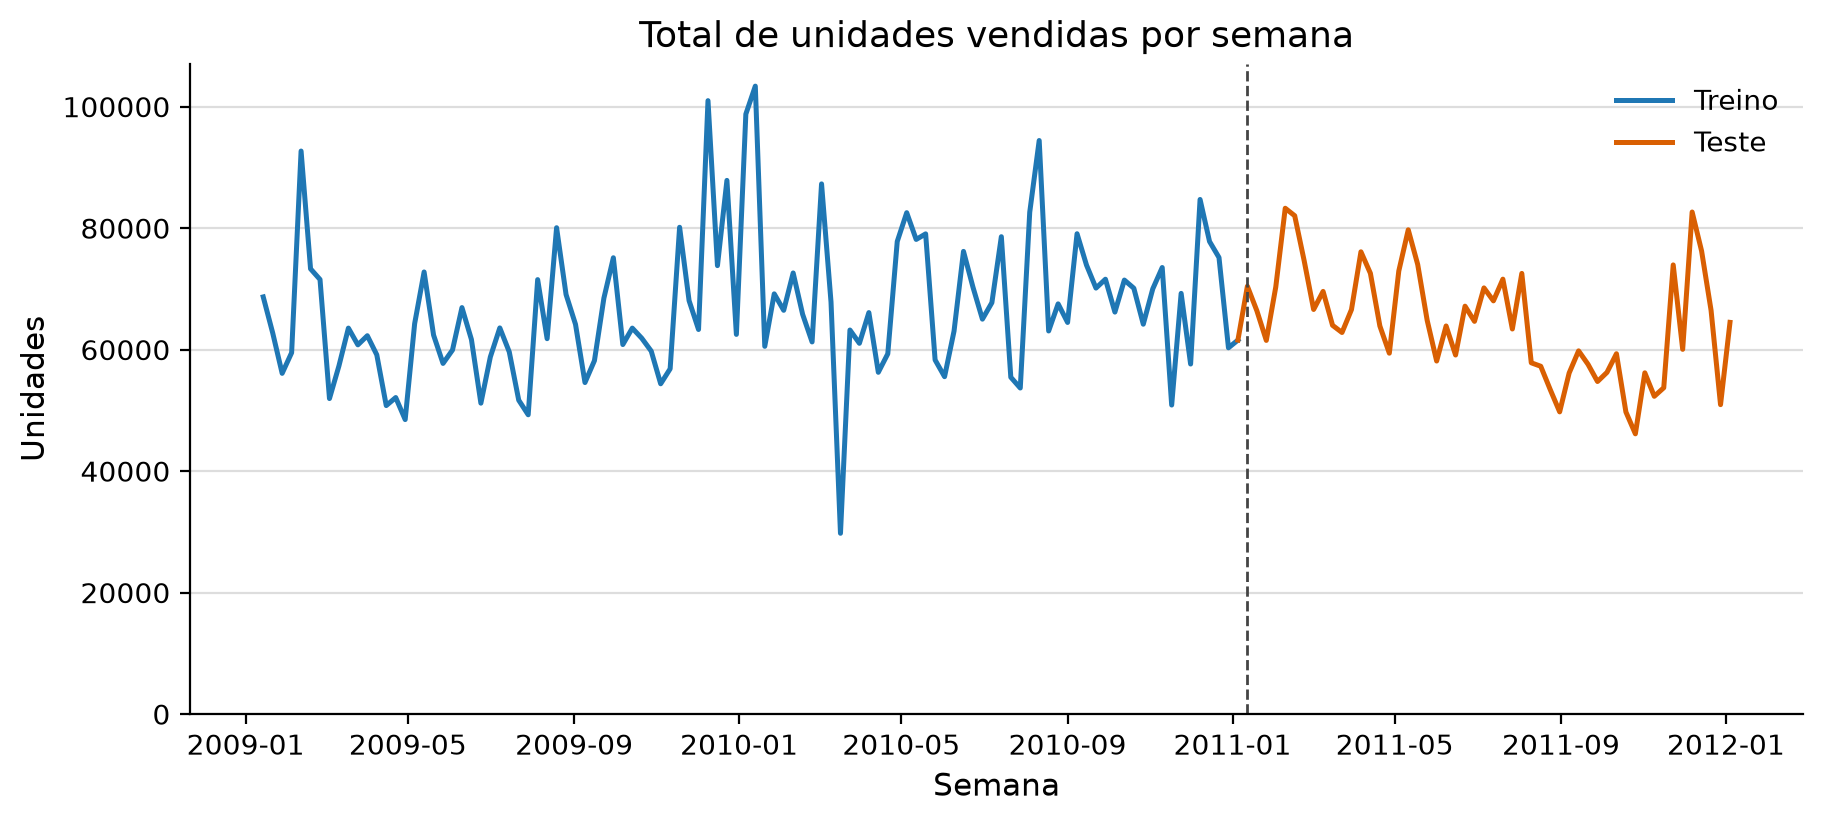

In [7]:
weekly = eda.weekly_units(panel)
fig = viz.plot_weekly_units(weekly, LANG)

In [8]:
split_sizes = pd.DataFrame(
    {"rows": [len(train), len(test)], "pairs": [train["PAIR_ID"].nunique(), test["PAIR_ID"].nunique()]},
    index=[t("legend_train", LANG), t("legend_test", LANG)],
)
display(split_sizes)
display(pd.Series({"pairs_only_in_test": len(set(test["PAIR_ID"]) - set(train["PAIR_ID"]))}).to_frame("n"))

,rows,pairs
Treino,347092,3859
Teste,177767,3870


,n
pairs_only_in_test,50


A amostra de treino tem 347.092 linhas em 3.859 pares, e a janela de avaliação tem 177.767 linhas em 3.870 pares. Cinquenta pares só aparecem na avaliação. Para esses pares, a parte aleatória da previsão usa os efeitos de loja e produto disponíveis, pois o par não tem histórico no treino.

## 3. Cobertura dos pares

O histograma conta as semanas de treino de cada par loja × produto.

,n_weeks_train
count,"3,859.000"
mean,89.944
std,22.830
min,1.000
25%,86.000
50%,102.000
75%,104.000
max,104.000


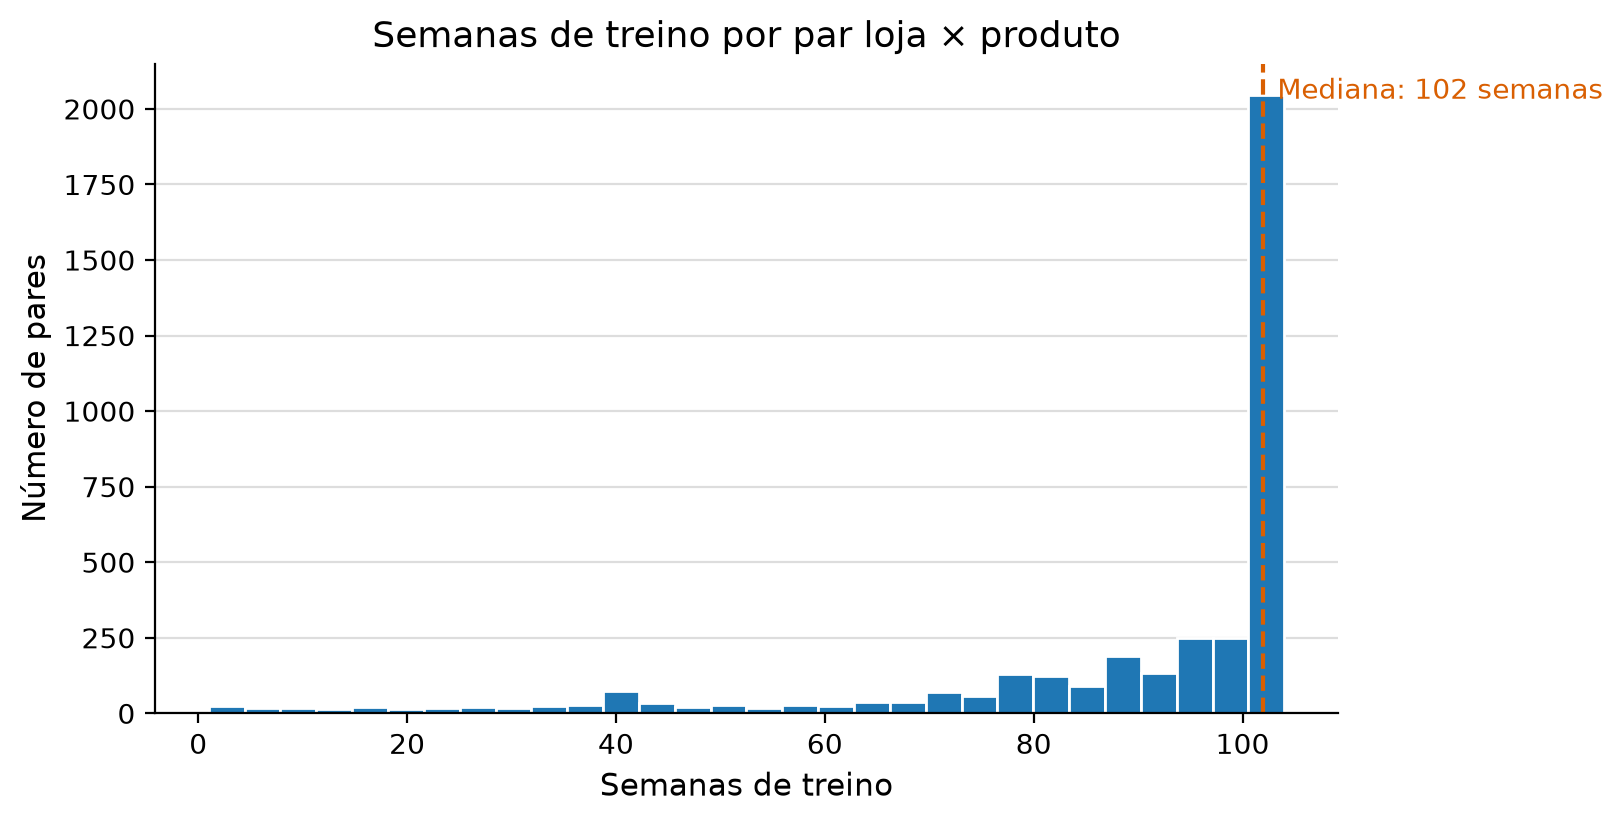

In [9]:
coverage = eda.pair_coverage(train)
fig = viz.plot_pair_coverage(coverage, LANG)
coverage["n_weeks_train"].describe().to_frame()

A mediana é de 102 semanas de treino por par, e 1.537 pares têm as 104 semanas. Um quarto dos pares tem até 86 semanas, e alguns têm uma só. Com *partial pooling*, os pares de histórico curto são estimados também com a informação dos demais.

## 4. Promoções

As taxas abaixo são a participação de linhas com cada promoção ligada, no painel inteiro, no total e por categoria. `BELOW_BASE` indica preço abaixo de 95% do preço base.

,FEATURE,DISPLAY,TPR_ONLY,ANY_PROMO,BELOW_BASE,n
all,0.084,0.110,0.135,0.285,0.247,524926


,FEATURE,DISPLAY,TPR_ONLY,ANY_PROMO,BELOW_BASE,n
CATEGORY,,,,,,
BAG SNACKS,0.025,0.128,0.163,0.304,0.230,127459
COLD CEREAL,0.096,0.088,0.110,0.237,0.221,169687
FROZEN PIZZA,0.167,0.147,0.086,0.307,0.270,111264
ORAL HYGIENE PRODUCTS,0.054,0.087,0.187,0.312,0.284,116516


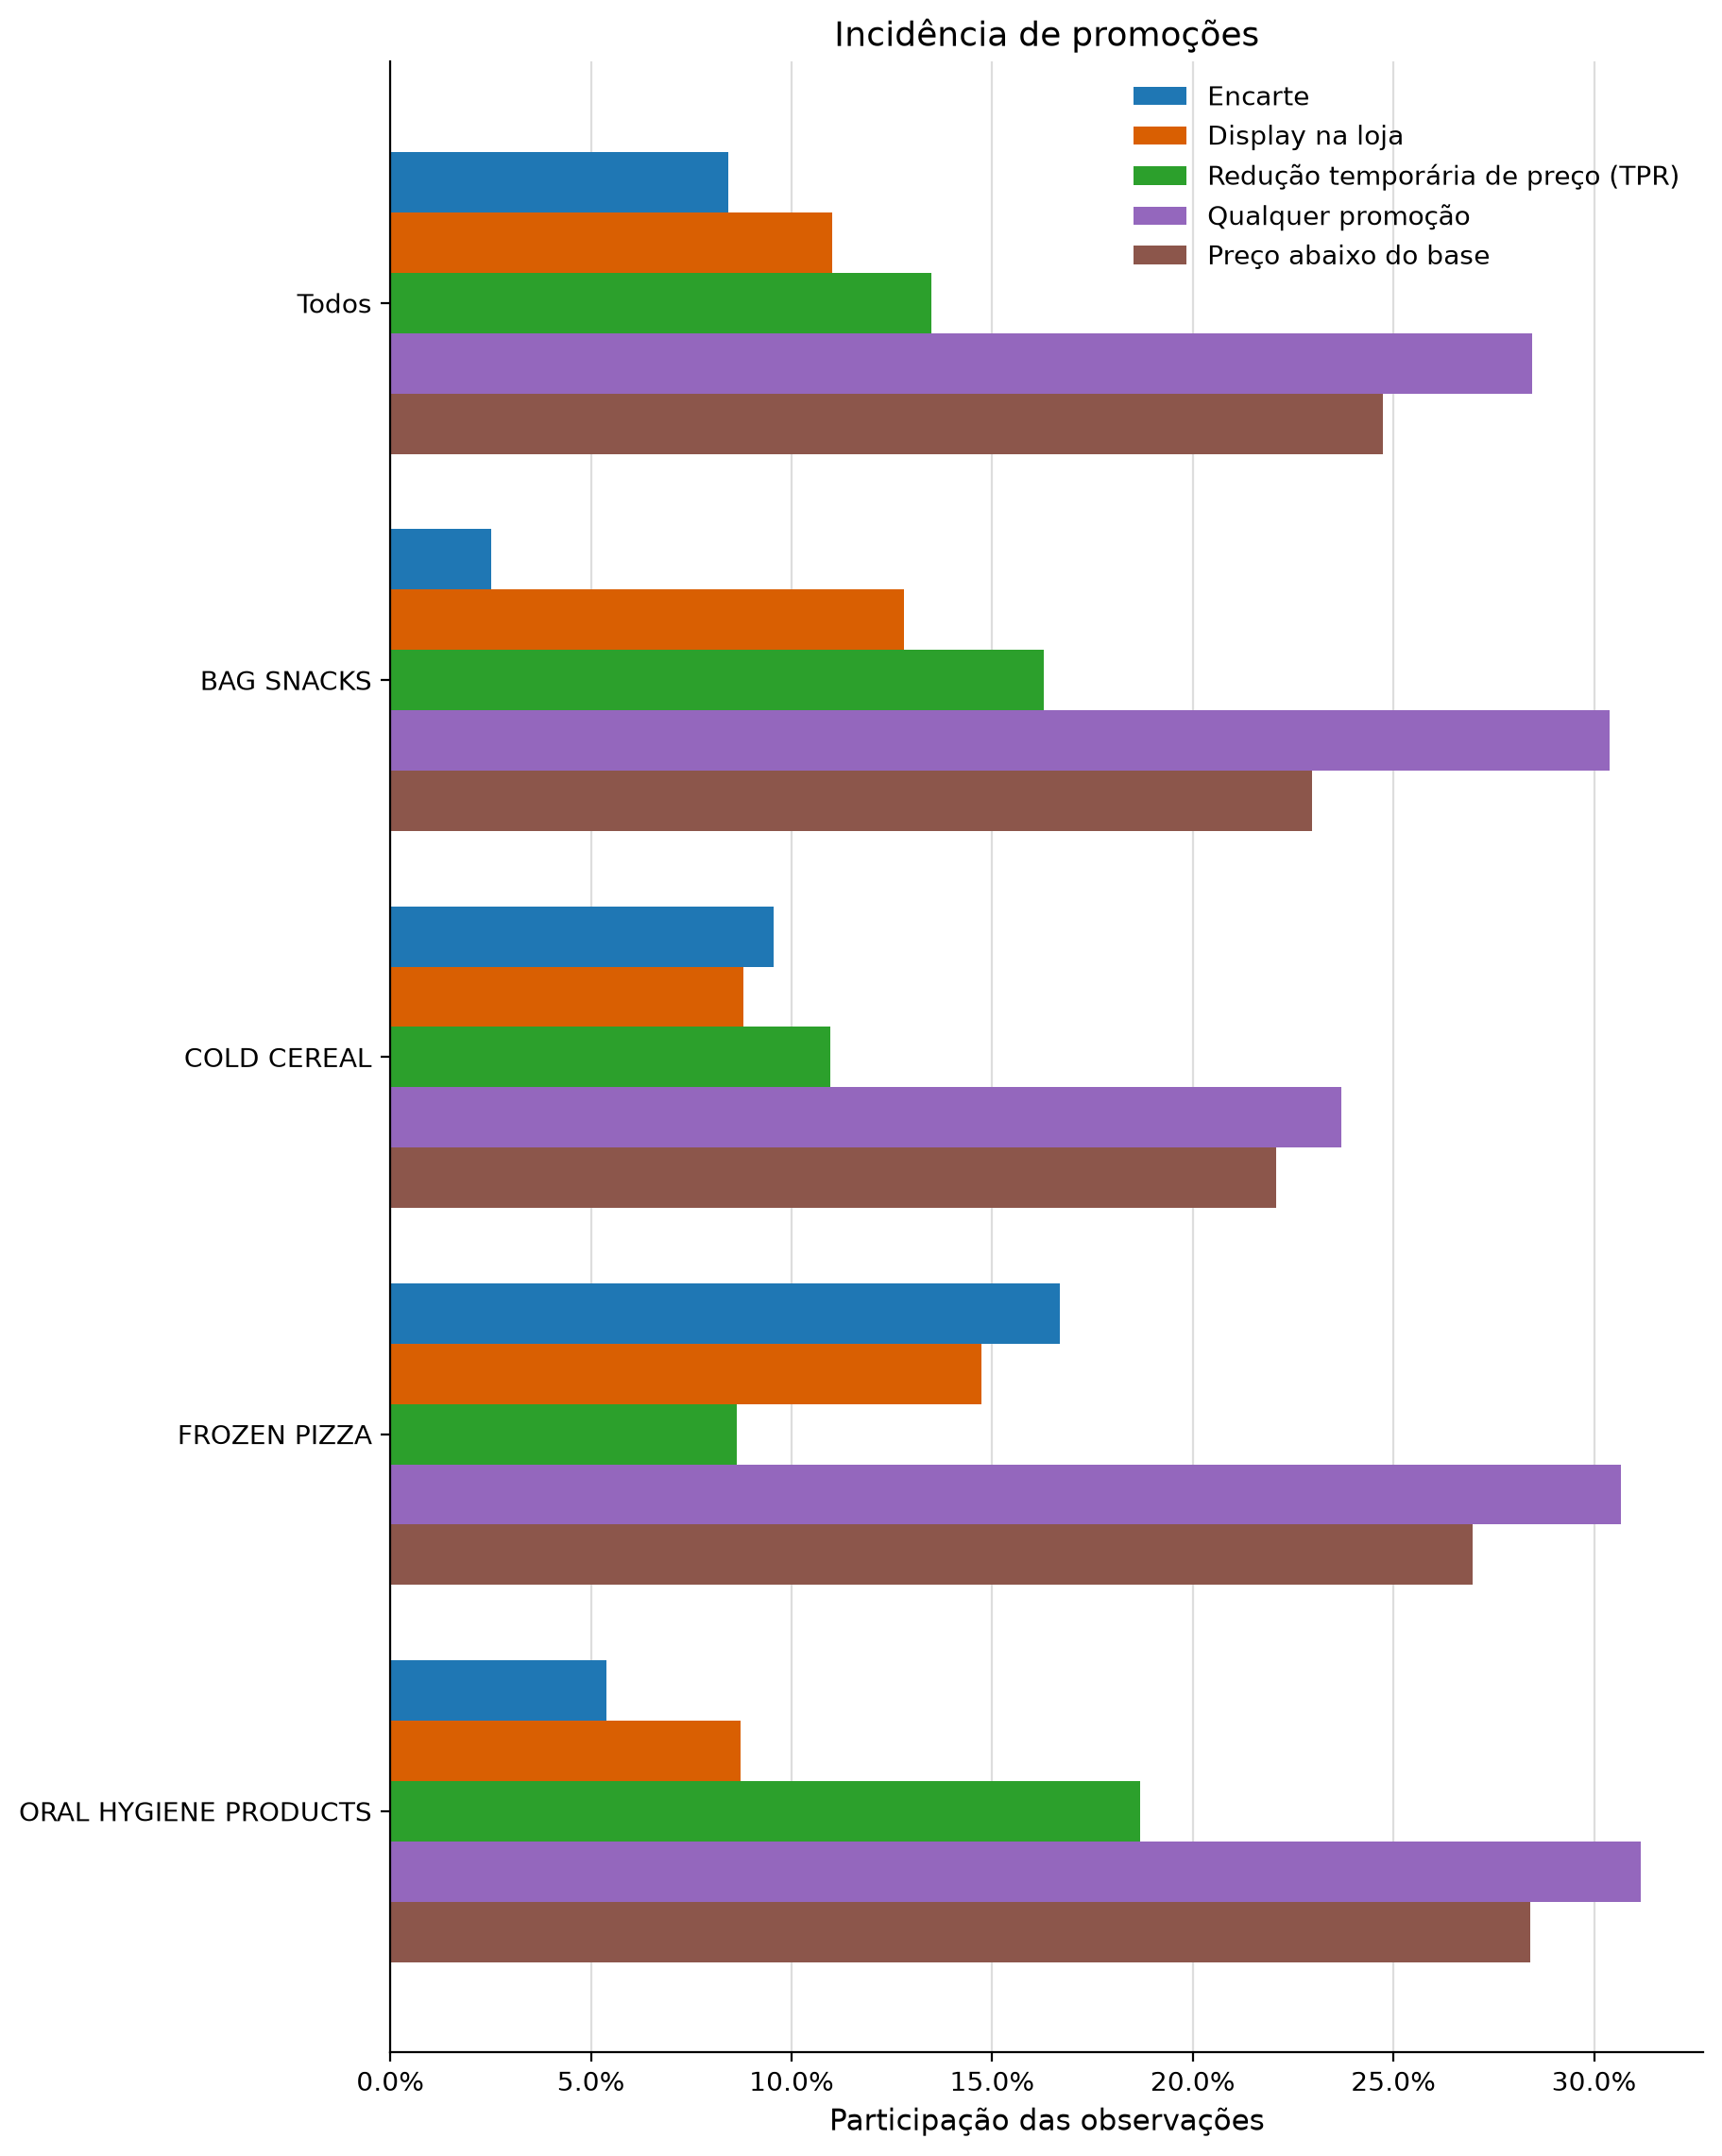

In [10]:
display(eda.promo_rates(panel))
rates_by_category = eda.promo_rates(panel, "CATEGORY")
display(rates_by_category)
fig = viz.plot_promo_rates(pd.concat([eda.promo_rates(panel), rates_by_category]), LANG)

In [11]:
tpr = panel["TPR_ONLY"].astype(bool).rename("TPR_ONLY")
feature_or_display = (panel["FEATURE"].astype(bool) | panel["DISPLAY"].astype(bool)).rename("FEATURE or DISPLAY")
display(pd.crosstab(tpr, feature_or_display))
below_base = (panel["PRICE"] < 0.95 * panel["BASE_PRICE"]).rename(t("promo_below_base", LANG))
any_promo = panel["ANY_PROMO"].astype(bool).rename(t("promo_any_promo", LANG))
display(pd.crosstab(below_base, any_promo))

FEATURE or DISPLAY,False,True
TPR_ONLY,,
False,375541,78652
True,70733,0


Qualquer promoção,False,True
Preço abaixo do base,,
False,375541,19555
True,0,129830


Há alguma promoção em 28,5% das linhas, com encarte em 8,4%, display em 11,0% e TPR em 13,5%. A primeira tabela confirma que `TPR_ONLY` nunca coincide com encarte ou display (0 linhas). A segunda mostra 129.830 linhas com preço abaixo de 95% do base, todas com promoção. As outras 19.555 linhas com promoção ficaram no limiar de 95% ou acima dele. A frequência de encarte varia por categoria, de 2,5% em snacks a 16,7% em pizza congelada.

## 5. Variação de preço

O desvio-padrão de `LOG_PRICE` mede quanta variação de preço dentro de cada par está disponível no treino para estimar a elasticidade.

In [12]:
variation = eda.price_variation(train)
variation[["sd_log_price", "share_below_base"]].describe()

,sd_log_price,share_below_base
count,"3,856.000","3,859.000"
mean,0.121,0.242
std,0.063,0.141
min,0.000,0.000
25%,0.079,0.132
50%,0.111,0.231
75%,0.156,0.327
max,0.876,0.990


A mediana do desvio-padrão de log(preço) dentro do par é de 0,111 (cerca de 11%). Em média, 24% das semanas de cada par têm preço abaixo de 95% do base. Essa variação concentra-se em semanas de promoção, o que dificulta distinguir a associação com preço da associação com encarte e display.

## 6. Participação descritiva na variância

Para cada agrupamento, calculou-se a fração da variância de `LOG_UNITS` que está entre os grupos (eta ao quadrado), na amostra de treino. O cálculo é descritivo e feito um agrupamento por vez; como loja, produto e par não são aninhados de forma exclusiva, as frações não somam 1.

,group,n_groups,between_share
0,STORE_NUM,77,0.067
1,UPC,55,0.533
2,PAIR_ID,3859,0.727


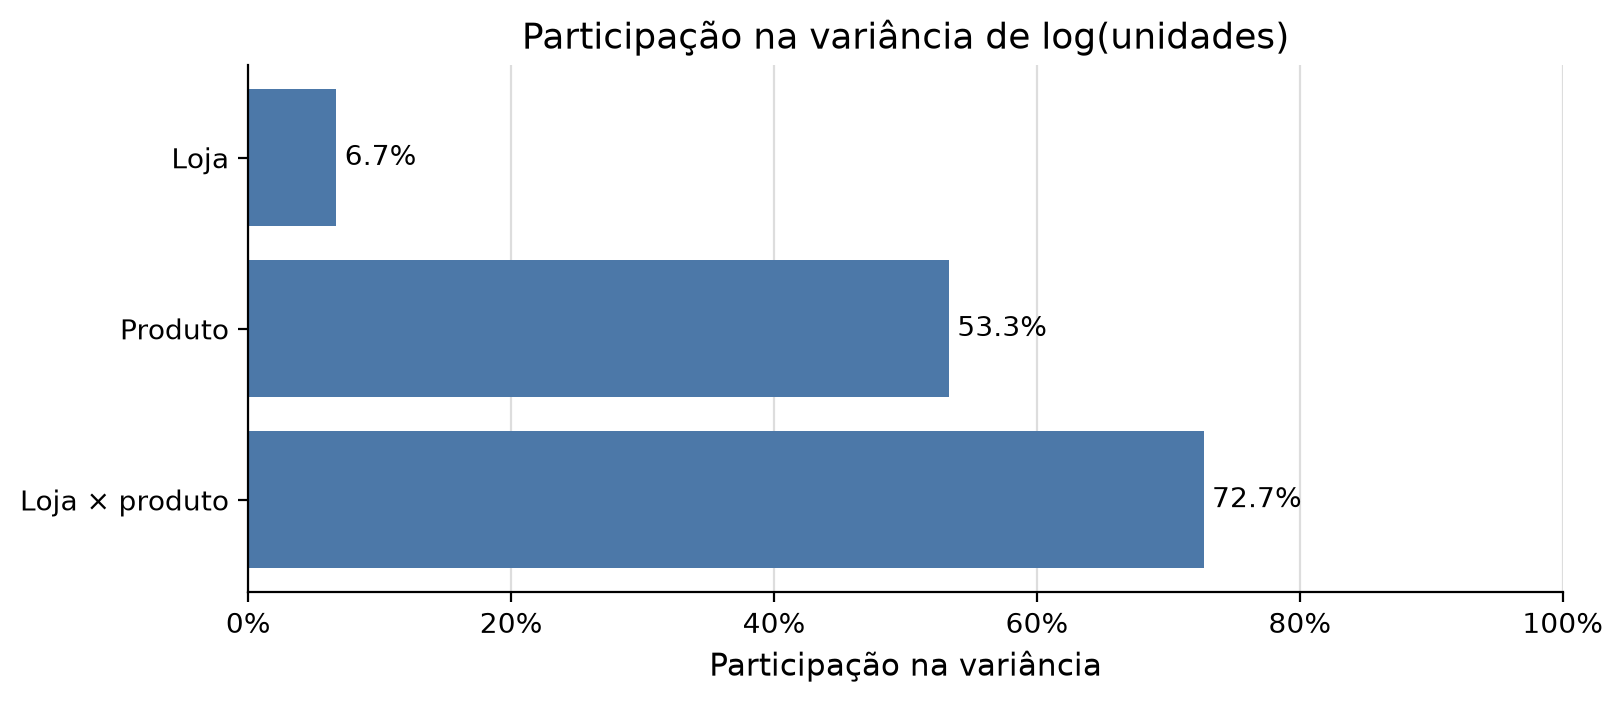

In [13]:
shares = eda.variance_shares(train)
display(shares)
fig = viz.plot_variance_shares(shares, LANG, share_col="between_share")

As diferenças entre as médias de cada produto respondem por 53,3% da variância de log(unidades), as diferenças entre lojas por 6,7% e as diferenças entre pares por 72,7%. As 3.859 médias de par incorporam diferenças de loja e produto e a interação entre os dois. O modelo nulo com efeitos aleatórios cruzados (Baayen et al., 2008), no notebook 02, estima componentes separados de loja, produto, interação e resíduo.

## 7. Lift bruto de promoção

O lift bruto compara, dentro de cada par, o log de unidades em semanas com cada promoção ligada com o das semanas sem nenhuma promoção (amostra de treino).

,lift_log,lift_pct,n_weeks
promo,,,
FEATURE,1.082,1.951,28964
DISPLAY,0.827,1.287,37756
TPR_ONLY,0.281,0.325,47610


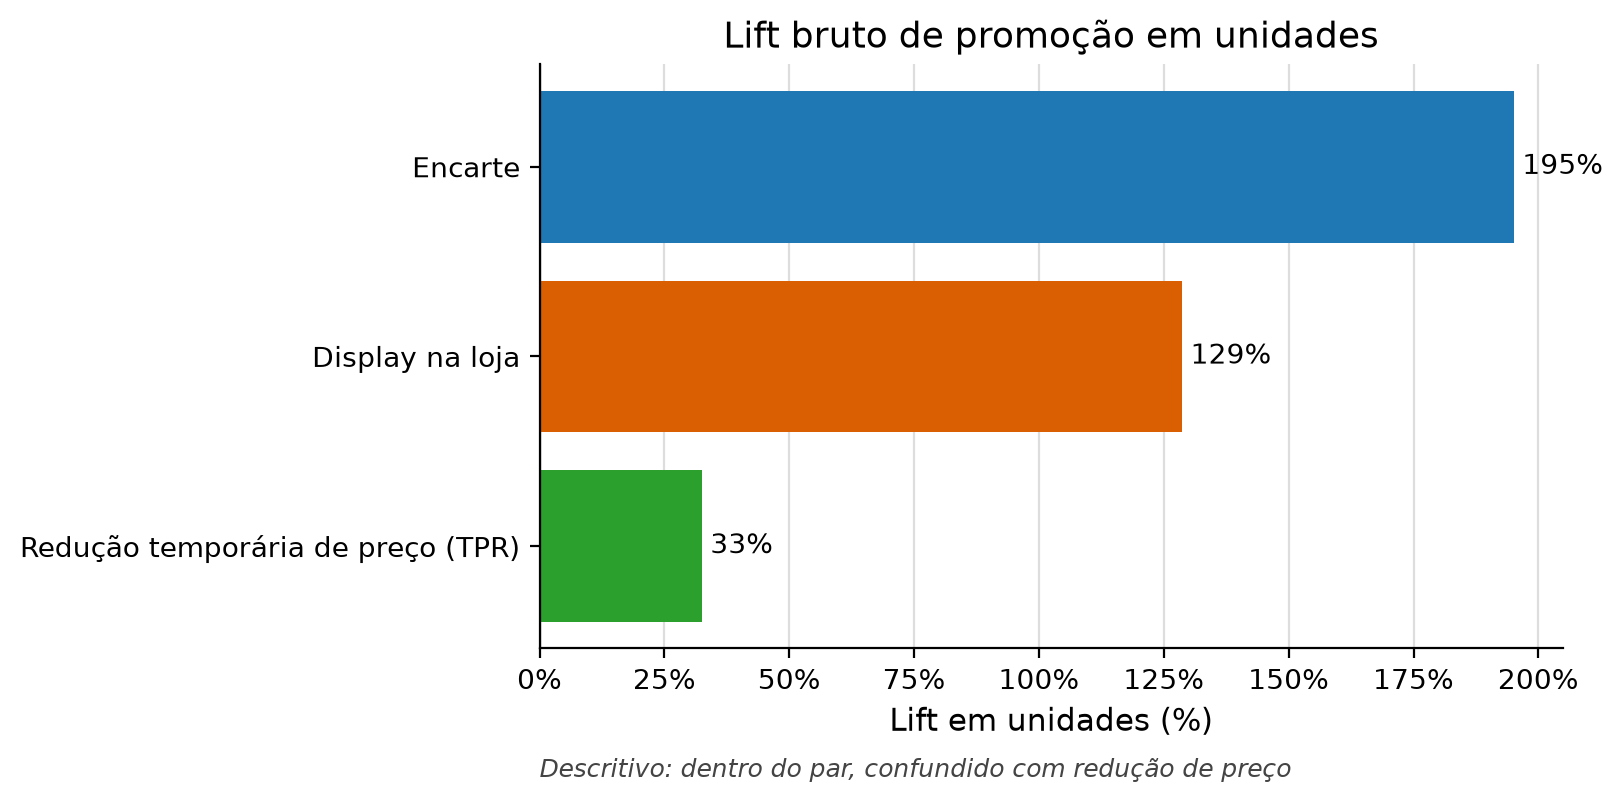

In [14]:
lift = eda.raw_promo_lift(train)
display(lift)
fig = viz.plot_raw_promo_lift(lift, LANG)

No treino, o lift bruto foi de 195% para encarte, 129% para display e 33% para TPR. A comparação descritiva inclui as reduções de preço, a ocorrência conjunta de encarte e display e a possibilidade de concentrar essas promoções em produtos ou semanas de maior demanda.

## 8. Inclinações do desconto estimadas par a par

Foi estimado um OLS para cada par loja × produto com ao menos 8 semanas de treino (semanas 0 a 103). A especificação é `LOG_UNITS ~ LOG_DISC + FEATURE + DISPLAY + TPR_ONLY`, com `LOG_DISC = log(preço / preço base)`. São omitidos termos constantes no par ou colineares com os anteriores. Se `LOG_DISC` for constante, o par fica sem inclinação estimada. Os resultados foram gravados por `scripts/fit_pair_ols_slopes.py`. Como `LOG_DISC` diminui quando o desconto aumenta, uma inclinação negativa associa descontos maiores a mais unidades. Uma inclinação positiva associa descontos maiores a menos unidades.

20261126-104604-bd48a521


,Estrato de histórico,Pares,Pares com inclinação > 0,Participação com inclinação > 0 (%),Percentil 5,Percentil 25,Mediana,Percentil 75,Percentil 95
0,Todos,3788,751,19.83,-5.40,-2.85,-1.65,-0.33,3.18
1,< 26 semanas,69,25,36.23,-10.54,-1.74,0.00,0.54,3.45
2,26-77 semanas,543,148,27.26,-6.89,-3.34,-1.52,0.21,5.61
3,≥ 78 semanas,3176,578,18.20,-4.86,-2.82,-1.68,-0.46,2.69


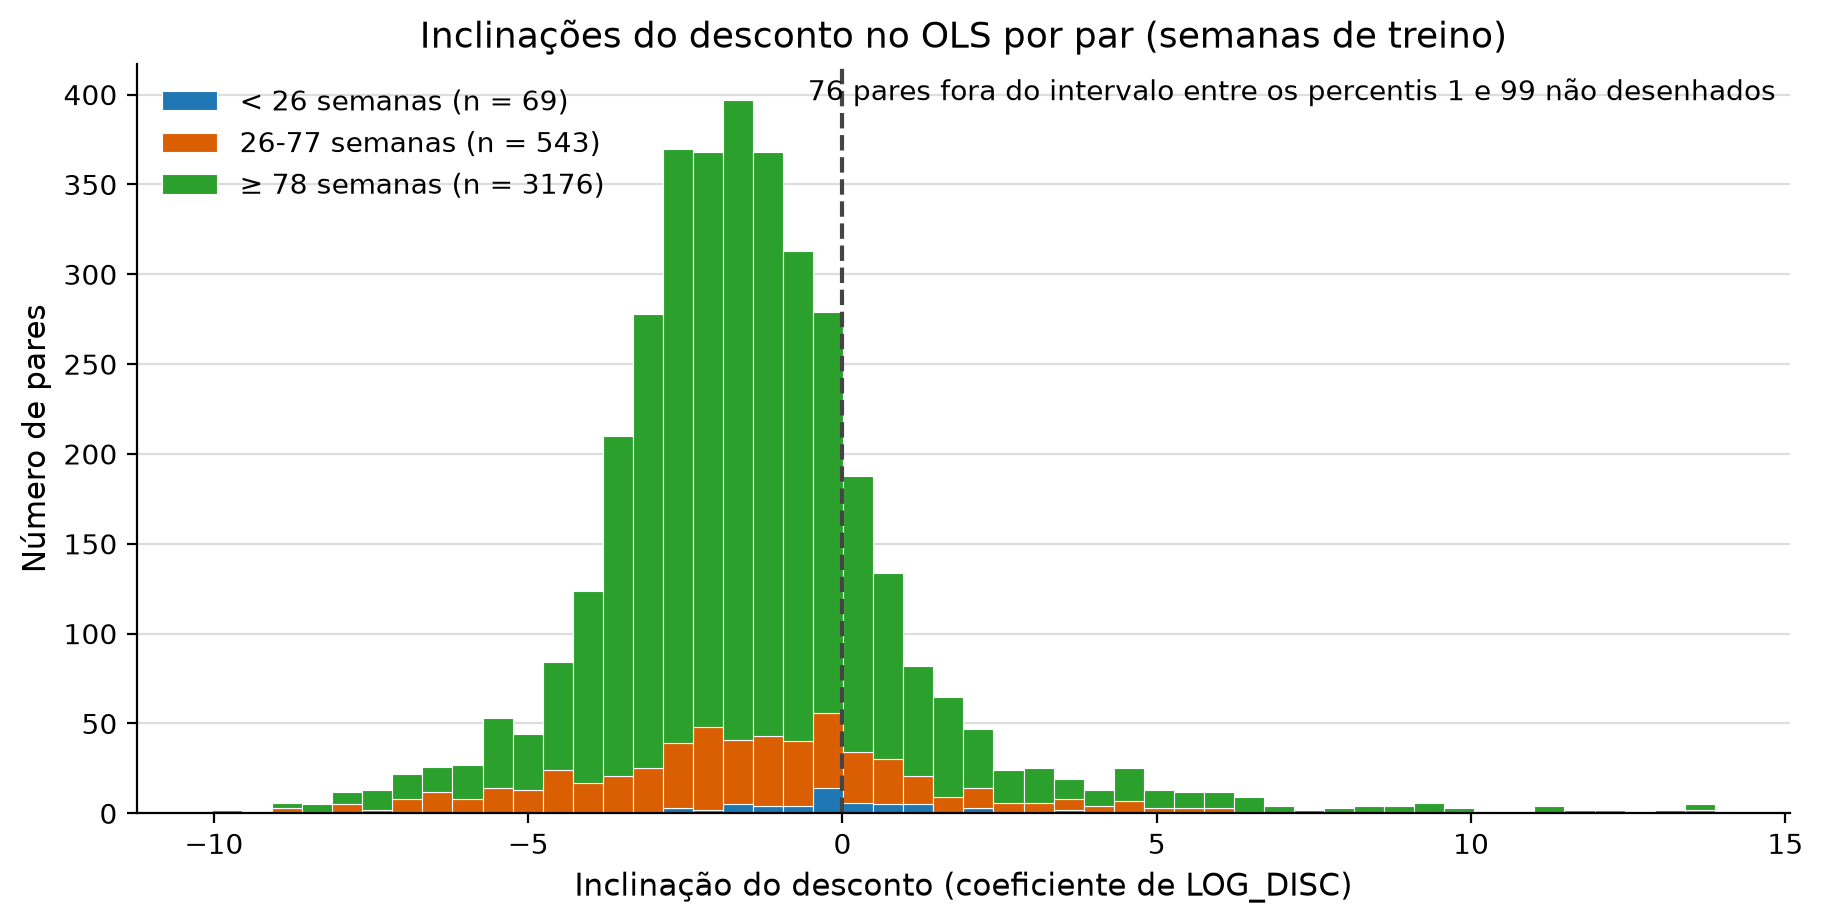

In [15]:
from retail_multilevel.i18n import localize_columns, stratum_label
from retail_multilevel.runs import load_run

pair_run = load_run("pair_ols_slopes", "20261126-104604-bd48a521")
print(pair_run.run_id)
pair_slopes = pair_run.load_table("slopes")
pair_summary = pair_run.load_table("summary")
pair_summary["stratum"] = [stratum_label(x, LANG) for x in pair_summary["stratum"]]
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(localize_columns(pair_summary, LANG))
fig = viz.plot_pair_slopes(pair_slopes, LANG)

Das 3.859 combinações de treino, 3.788 tiveram a inclinação do desconto estimada: 42 pares têm menos de 8 semanas e 29 foram ajustados sem variação de desconto estimável. A mediana das inclinações é de −1,65, mas a dispersão é grande, com o percentil 5 em −5,40 e o percentil 95 em +3,18. Um total de 751 pares (19,8%) tem inclinação positiva. A participação é de 36,2% nos pares com menos de 26 semanas (25 de 69), de 27,3% nos de 26 a 77 semanas (148 de 543) e de 18,2% nos de 78 semanas ou mais (578 de 3.176). Ela diminui com o histórico, mas ainda alcança quase um par em cada cinco entre os mais longos. Inclinações exatamente nulas, que ocorrem em pares com unidades constantes, e coeficientes nulos a menos de arredondamento não são contados como positivos.

Uma inclinação positiva vai na direção oposta à relação de demanda esperada. Em um par isolado, ela pode refletir poucas semanas com desconto ou fatores como a época das promoções. Essa dispersão motiva o uso de *partial pooling* nos notebooks 02 a 04 (Gelman & Hill, 2007).

## 9. Resumo

O painel tem 524.926 linhas, 77 lojas, 55 produtos, 3.909 pares e 156 semanas, e a amostra de modelagem exclui 67 linhas. As últimas 52 semanas formam a janela de avaliação retrospectiva, com exposição exploratória prévia, e 50 pares só aparecem nesse período. O painel de treino é desbalanceado (mediana de 102 semanas por par), o que favorece o *partial pooling*. Estimadas par a par, 19,8% das inclinações do desconto são positivas, o que reforça essa motivação.

Em 28,5% das linhas há alguma promoção. Todo preço abaixo de 95% do base foi observado em semanas com promoção, e `TPR_ONLY` ocorre sem encarte nem display. O lift bruto combina a associação promocional com a de preço. Na análise descritiva de log(unidades), produtos e pares respondem pelas maiores frações de variância entre grupos. Essas frações não são aditivas.

O notebook 02 lê os modelos nulos ajustados por script (`runs.load_run("null_models", "20261124-114105-b15be79c")`) e decompõe a variância entre loja, produto, interação e resíduo.

## Referências

Baayen, R. H., Davidson, D. J., & Bates, D. M. (2008). Mixed-effects modeling with crossed random effects for subjects and items. *Journal of Memory and Language, 59*(4), 390–412. https://doi.org/10.1016/j.jml.2007.12.005

Bijmolt, T. H. A., van Heerde, H. J., & Pieters, R. G. M. (2005). New empirical generalizations on the determinants of price elasticity. *Journal of Marketing Research, 42*(2), 141–156. https://doi.org/10.1509/jmkr.42.2.141.62296

Blattberg, R. C., & Neslin, S. A. (1989). Sales promotion: The long and the short of it. *Marketing Letters, 1*(1), 81–97. https://doi.org/10.1007/BF00436151

Gelman, A., & Hill, J. (2007). *Data analysis using regression and multilevel/hierarchical models*. Cambridge University Press. https://doi.org/10.1017/CBO9780511790942

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/

Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606. https://doi.org/10.1073/pnas.1708274114

Raudenbush, S. W., & Bryk, A. S. (2002). *Hierarchical linear models: Applications and data analysis methods* (2nd ed.). Sage. (verificação parcial: ano da edição não conferido em fonte primária)

Sigrist, F. (2022). Gaussian process boosting. *Journal of Machine Learning Research, 23*, 1–46.

Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: An analysis and review. *International Journal of Forecasting, 16*(4), 437–450. https://doi.org/10.1016/S0169-2070(00)00065-0

Tellis, G. J. (1988). The price elasticity of selective demand: A meta-analysis of econometric models of sales. *Journal of Marketing Research, 25*(4), 331–341. https://doi.org/10.1177/002224378802500401

Weston, S. J., Ritchie, S. J., Rohrer, J. M., & Przybylski, A. K. (2019). Recommendations for increasing the transparency of analysis of preexisting data sets. *Advances in Methods and Practices in Psychological Science, 2*(3), 214–227. https://doi.org/10.1177/2515245919848684